In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name=0)

print("Dataset shape:", data.shape)
print("\nFirst five rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

Dataset shape: (9568, 5)

First five rows:
      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41


In [ ]:
# Descriptive statistics of the dataset
print("Descriptive Statistics:")
display(data.describe().round(2))

# Check data types
print("\nData Types:")
print(data.dtypes)

Descriptive Statistics:


,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76



Data Types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object


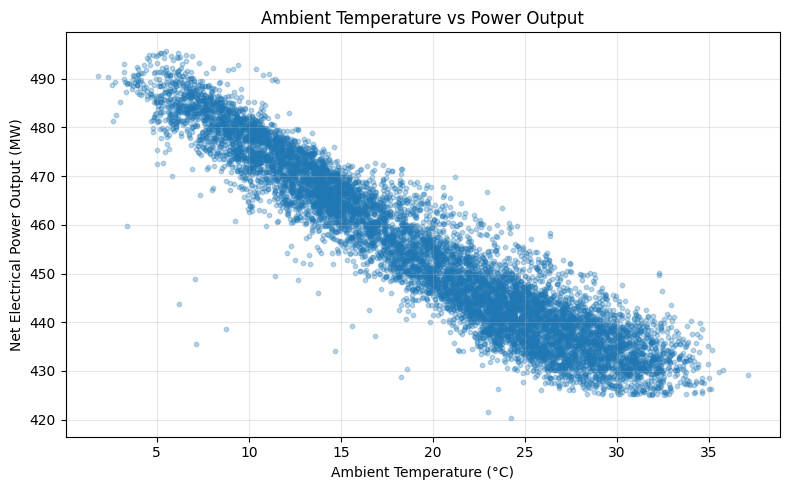

In [ ]:
# Relationship between ambient temperature and power output

plt.figure(figsize=(8, 5))

plt.scatter(data["AT"], data["PE"], alpha=0.3, s=10)

plt.xlabel("Ambient Temperature (°C)")
plt.ylabel("Net Electrical Power Output (MW)")
plt.title("Ambient Temperature vs Power Output")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

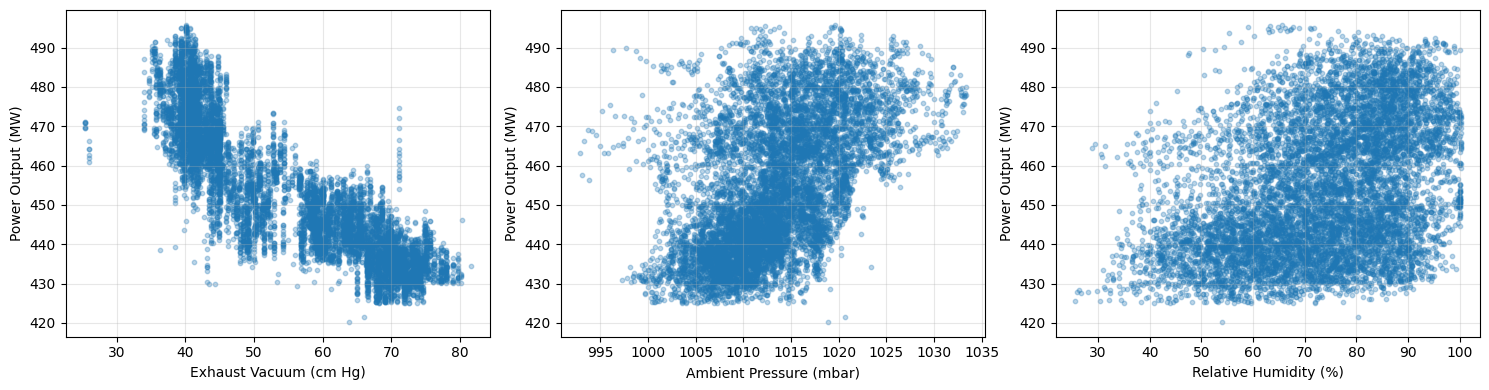

In [ ]:
# Relationships between other input variables and power output

variables = ["V", "AP", "RH"]

labels = [
    "Exhaust Vacuum (cm Hg)",
    "Ambient Pressure (mbar)",
    "Relative Humidity (%)"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
  axes[i].scatter(
      data[variables[i]],
      data["PE"],
      alpha=0.3,
      s=10
  )

  axes[i].set_xlabel(labels[i])
  axes[i].set_ylabel("Power Output (MW)")
  axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation coefficients

correlation = data.corr()

print("Correlation with Power Output (PE):")
print(correlation["PE"].round(3))

Correlation with Power Output (PE):
AT   -0.948
V    -0.870
AP    0.518
RH    0.390
PE    1.000
Name: PE, dtype: float64


In [ ]:
# Check duplicated rows
print("Number of duplicate rows:")
print(data.duplicated().sum())

print("\nExamples of duplicated rows:")
display(data[data.duplicated(keep=False)].head(10))

# Check relative humidity values above 100%
print("\nNumber of RH values above 100%:")
print((data["RH"] > 100).sum())

print("\nRows with RH above 100%:")
display(data[data["RH"] > 100])

Number of duplicate rows:
41

Examples of duplicated rows:


,AT,V,AP,RH,PE
231,26.85,75.60,1017.43,74.55,433.48
345,12.19,41.17,1019.43,65.47,475.64
352,25.56,75.60,1017.37,69.31,442.20
468,25.21,75.60,1017.19,69.84,445.84
726,28.41,75.60,1018.48,56.07,440.28
806,6.86,41.17,1020.12,79.14,490.23
1186,6.06,41.17,1019.67,84.70,489.62
1291,27.54,75.60,1018.26,57.89,440.87
1482,12.11,41.17,1019.46,62.59,475.53
1551,8.57,41.17,1020.18,72.47,484.20



Number of RH values above 100%:
55

Rows with RH above 100%:


,AT,V,AP,RH,PE
124,15.22,50.88,1014.19,100.12,460.44
166,18.14,49.78,1002.95,100.09,451.44
179,18.06,50.16,1009.52,100.09,450.53
297,11.60,39.10,1009.81,100.09,460.70
379,10.73,25.36,1009.35,100.15,469.43
711,12.87,48.04,1012.47,100.13,465.56
1013,19.11,50.16,1010.88,100.09,450.38
1829,19.04,50.12,1010.53,100.09,446.59
2338,18.17,52.08,1001.91,100.09,451.06
2784,18.11,52.08,1002.51,100.09,449.99


In [ ]:
# Remove duplicate rows
clean_data = data.drop_duplicates().copy()

# Compare original and cleaned datasets
print("Original dataset rows:", len(data))
print("Duplicate rows removed:", len(data) - len(clean_data))
print("Cleaned dataset rows:", len(clean_data))

# Check remaining missing values
print("\nMissing values:")
print(clean_data.isnull().sum())

# Display the first five cleaned rows
print("\nFirst five cleaned rows:")
display(clean_data.head())

Original dataset rows: 9568
Duplicate rows removed: 41
Cleaned dataset rows: 9527

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

First five cleaned rows:


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
